## AIS ETA Deviation Analysis
In this notebook we'll analyze ETA discrepancies across Cargo, Tanker and Passenger vessels using AIS observations processed by the project's ETL pipeline and stored in a PostgreSQL database.  
  
The analysis estimates ETA with a simple model using Haversine Distance and Speed Over Ground(SOG). The calculated ETA is then compared against each observation's reported ETA.  
  
The primary objectives are to:
- Quantify the difference between reported and calculated ETAs
- Compare discrepancy patterns across different vessel types  
  
Note: The calculated ETA assumes straight-line travel at near constant speeds. Actual vessel routes and verified arrival timestamps are not modeled/included therefore these discrepancies should not be mistaken as direct measures of arrival prediction accuracy.

In [1]:
import os
import pandas as pd
import numpy as np
import psycopg
from dotenv import load_dotenv
import seaborn as sns
import matplotlib.pyplot as plt

load_dotenv()

with psycopg.connect(dbname=os.getenv('DB_NAME'), user=os.getenv('DB_USER'), 
   password=os.getenv('DB_PASSWORD'), host=os.getenv('DB_HOST'), port=os.getenv('DB_PORT')) as conn:

    imported = pd.read_sql_query("""
       SELECT ship_type, timestamp, mmsi, dest_lat,
       dest_lon, latitude, longitude, sog, eta
       FROM vessel_eta
       WHERE class IS NOT NULL AND
       dest_lat IS NOT NULL AND
       dest_lon IS NOT NULL AND
       sog > 0;
    """, con=conn)

print(imported.duplicated().sum())

C:\Users\andro\AppData\Local\Temp\ipykernel_48344\2220919414.py:14: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  imported = pd.read_sql_query("""


4390340


Our queried dataframe contains a substantial amount of duplicates. Since identical observations would produce identical distance estimates and ETA deviations, retaining them would wrongfully weight repeated records in the analysis.

In [2]:
imported = imported.drop_duplicates().reset_index()
print(imported.shape[0])
print(imported.duplicated().sum())

2669603
0


## Distance And ETA Estimation
Our next step is crucial for the analysis. We'll be implementing a haversine function which calculates the great-circle distance between each vessel's reported coordinates and its mapped destination coordinates using the haversine formula.

The calculation uses the destination coordinates produced by our ETL pipeline. Earth's radius is approximated as 6,371 km and the resulting distances are expressed in kilometers.

Note: Haversine distance represents the shortest path over a spherical Earth. It does not account for coastlines, shipping lanes or other route constraints. Therefore, it provides a simplified distance baseline rather than an estimate of the actual maritime route length.

In [3]:
pd.set_option('display.float_format', lambda x: f"{x:.2f}")

def haversine_distance(ves_lat: float, ves_lon: float, dest_lat: float, dest_lon: float) -> float:

    R_km = 6371

    lat1 = ves_lat * (np.pi/180)
    lat2 = dest_lat * (np.pi/180)
    lon1 = ves_lon * (np.pi/180)
    lon2 = dest_lon * (np.pi/180)

    d_lat = lat2 - lat1
    d_lon = lon2 - lon1

    a = (np.sin(d_lat/2))**2 + np.cos(lat1) * np.cos(lat2) * (np.sin(d_lon/2))**2
    c = 2 * np.arcsin(np.sqrt(a))
    d = R_km * c

    return d

imported['distance_km'] = haversine_distance(imported['latitude'], imported['longitude'], imported['dest_lat'], imported['dest_lon'])
print(imported['distance_km'].describe())
outliers = imported['distance_km'].sort_values(ascending=False).head(40000)
outliers_df = imported[imported.index.isin(outliers.index)]
print(outliers_df['mmsi'].unique())
print(imported[imported['mmsi'] == '538005945'])

count   2669603.00
mean       1010.33
std        1870.03
min           0.01
25%         169.01
50%         401.41
75%         831.32
max       10996.02
Name: distance_km, dtype: float64
['538005945' '538003632' '215662000' '229200000' '636018372' '636018331']
           index ship_type           timestamp       mmsi  dest_lat  dest_lon  \
639         2540     Cargo 2024-08-07 00:02:03  538005945    -20.32    -40.32   
686         2709     Cargo 2024-08-07 00:02:08  538005945    -20.32    -40.32   
789         3141     Cargo 2024-08-07 00:02:18  538005945    -20.32    -40.32   
890         3559     Cargo 2024-08-07 00:02:28  538005945    -20.32    -40.32   
1011        4047     Cargo 2024-08-07 00:02:38  538005945    -20.32    -40.32   
...          ...       ...                 ...        ...       ...       ...   
2668419  7057460     Cargo 2024-08-07 23:59:17  538005945    -20.32    -40.32   
2668709  7058072     Cargo 2024-08-07 23:59:28  538005945    -20.32    -40.32   
2668982  70

Our haversine function produced some genuinely large distances inside our dataframe which are completely expected. One example is a cargo vessel embarking on a voyage from Samso in Denmark and heading to Vitoria in Brazil. Our next step is evaluating ETAs based on our model. Sidenote: keep in mind SOG is expressed in knots so we'll need to convert it to km/h to match our haversine distance unit(1kn = 1.852km/h).

In [4]:
imported['travel_time_hours'] = imported['distance_km'] / (imported['sog'] * 1.852)
print(imported['travel_time_hours'].describe())
eta_outliers = imported['travel_time_hours'].sort_values(ascending=False).head(4000)
eta_outliers_df = imported[imported.index.isin(eta_outliers.index)]
print(eta_outliers_df['travel_time_hours'].describe())
print(eta_outliers_df['mmsi'].unique())
print(imported['sog'].describe())
print(eta_outliers_df['sog'].describe())
print(imported['sog'][imported['mmsi'] == '218800000'].describe())

count   2669603.00
mean         51.61
std         131.17
min           0.00
25%           8.37
50%          18.49
75%          40.46
max       32137.86
Name: travel_time_hours, dtype: float64
count    4000.00
mean     2038.11
std      1435.46
min       888.41
25%      1127.44
50%      1597.09
75%      2460.62
max     32137.86
Name: travel_time_hours, dtype: float64
['230982000' '245266000' '247386800' '275491000' '538003632' '210017000'
 '244130525' '255915584' '271042567' '211317180' '636020098' '215767000'
 '218800000' '257222000' '636022780' '351639000' '636023864' '538006842'
 '314512000' '305167000' '244575000' '636019410' '245088000' '248275000'
 '215662000' '305981000' '305201000' '257988000' '212153000' '275510000'
 '219031310' '266203000' '212499000' '211833390' '256672000' '257207000'
 '236111817' '305943000' '209467000' '538005945' '210510000' '266331000'
 '244700336' '209168000' '258824000' '245257000' '236710000' '538003690'
 '258622000' '244321000' '258042000' '247019600'

Our current model has one caveat. Although most the time its estimates are entirely reasonable e.x. 18.49h, 40.46h, some of them arent exactly plausible **cough cough 32.137.86h. The reason we have produced such estimates is because vessels do not maintain stable speeds all the time. Take the vessel from the last print() statement for example. Its reported SOG seems completely normal. But if you look closely there are some slowdowns like 0.1kn. When our model is faced with these low speeds it produces enormous travel times. NOAA's AIS processing guidance uses 0.5 kn as the beginning of purposeful motion. Instead of simply filtering out speeds below a certain threshold a more sensible fix would be to calculate an hourly median SOG in order to smooth out noisy SOG values and keep out insignificant speeds below 0.5kn.

In [5]:
hourly = imported.groupby(['mmsi', 'dest_lat', 'dest_lon']).resample('1h', on='timestamp')['sog'].median().reset_index()
hourly = hourly[hourly['sog'] >= 0.5].reset_index(drop=True)
print(hourly['sog'].describe())
print(hourly.shape[0])
print(hourly['mmsi'].nunique())
print(hourly['sog'].isna().sum())

count   8026.00
mean      11.06
std        3.20
min        0.50
25%        9.50
50%       11.00
75%       12.60
max       28.00
Name: sog, dtype: float64
8026
631
0


In order to pick an observation to assign each hourly sog to we'll pick the observation of each vessel closest to the midpoint of that hour.

In [ ]:
imported['hour'] = imported['timestamp'].dt.floor('h')
hourly = hourly.rename(columns={
    'timestamp' : 'hour',
    'sog' : 'hourly_sog'
})
imported_hourly = imported.merge(hourly, how='inner', on=['mmsi', 'hour', 'dest_lat', 'dest_lon'])
print(imported_hourly.shape)
imported_hourly['midpoint_diff'] = (imported_hourly['timestamp'] - (imported_hourly['hour'] + pd.Timedelta(minutes=30))).abs()
idx = imported_hourly.groupby(['mmsi', 'hour'])['midpoint_diff'].idxmin()
hourly_representative = imported_hourly.loc[idx].reset_index(drop=True)
hourly_representative['estimated_hours'] = hourly_representative['distance_km'] / (hourly_representative['hourly_sog'] * 1.852)
print(hourly_representative)
print(hourly_representative['estimated_hours'].describe())

(2659435, 14)
        index ship_type           timestamp       mmsi  dest_lat  dest_lon  \
0     5703276     Cargo 2024-08-07 18:44:32  205106000     54.35     18.67   
1     5914809     Cargo 2024-08-07 19:29:58  205106000     54.35     18.67   
2     6192907     Cargo 2024-08-07 20:29:59  205106000     54.35     18.67   
3     6450712     Cargo 2024-08-07 21:29:59  205106000     54.35     18.67   
4     6710206     Cargo 2024-08-07 22:29:59  205106000     54.35     18.67   
...       ...       ...                 ...        ...       ...       ...   
8021  5884051     Cargo 2024-08-07 19:23:23  636092742     53.90     14.25   
8022  6451079     Cargo 2024-08-07 21:30:03  636092742     53.90     14.25   
8023  6705811     Cargo 2024-08-07 22:28:55  636092742     53.90     14.25   
8024   194026     Cargo 2024-08-07 00:29:59  636093027     54.35     18.67   
8025   642124     Cargo 2024-08-07 01:29:58  636093027     54.35     18.67   

      latitude  longitude   sog                 e

Our revised model is working a lot better. We can see that remaining hours like 32k has gone down to 1830 hours which is still 76 days but we cannot guarantee 100% accuracy. Another example is vessel 636092742. Its original estimated time was 60.72h while its revised estimated time is 8.99h. Our next step would be to measure the discrepancy between the reported ETA and the revised estimate.

In [7]:
hourly_representative['reported_hours'] = (hourly_representative['eta'] - hourly_representative['timestamp']).dt.total_seconds() / 3600
hourly_representative['eta_discrepancy'] = hourly_representative['estimated_hours'] - hourly_representative['reported_hours']
print(hourly_representative['eta_discrepancy'].describe())
worst300 = hourly_representative.sort_values('eta_discrepancy', ascending=True).head(300)
print(worst300)
print(hourly_representative['reported_hours'].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]))

count    8026.00
mean     -284.56
std      1321.42
min     -8594.14
25%       -20.50
50%        -4.30
75%        -0.59
max      1312.70
Name: eta_discrepancy, dtype: float64
        index  ship_type           timestamp       mmsi  dest_lat  dest_lon  \
686   2721127  Passenger 2024-08-07 06:48:38  211240870     54.33     10.13   
6566  3391488     Tanker 2024-08-07 09:30:02  354190000     53.90     14.25   
5577  6350511      Cargo 2024-08-07 21:06:40  305059000     56.15     10.22   
1308  1498455  Passenger 2024-08-07 03:30:01  219000584     55.88     11.13   
1309  1860341  Passenger 2024-08-07 04:23:53  219000584     55.88     11.13   
...       ...        ...                 ...        ...       ...       ...   
1396  4590966  Passenger 2024-08-07 14:29:53  219017917     54.94     10.71   
1397  4849254  Passenger 2024-08-07 15:30:05  219017917     54.94     10.71   
1398  5108640  Passenger 2024-08-07 16:30:04  219017917     54.94     10.71   
1399  5368827  Passenger 2024-08-07 

The discrepancy distribution is pretty conflicted. Inspecting the 300 smallest discrepancies (counting negatives) we can see that these observations are not exactly accurate. A vessel cannot have an ETA of over 1 year let alone be this close to port during that time. These observations suggest malformed ETAs or false crew input. However some of them could genuinely be long-distance voyages. In order to avoid ruling these out we'll use a distance + eta filter. Id say an eta of over 1 month combined with a distance of less than 1000km is a pretty reasonable filter.

In [8]:
suspect_eta = hourly_representative[(hourly_representative['distance_km'] < 1000) & (hourly_representative['reported_hours'] > 720)]
print(suspect_eta.shape[0])
print(worst300.index.isin(suspect_eta.index).sum())
hourly_representative = hourly_representative[~hourly_representative.index.isin(suspect_eta.index)]
print(hourly_representative['eta_discrepancy'].describe())

361
278
count    7665.00
mean      -32.57
std       264.92
min     -4860.75
25%       -14.69
50%        -3.78
75%        -0.48
max      1312.70
Name: eta_discrepancy, dtype: float64


The filtering has meaningfully improved our discrepancy distribution. However some negative extreme values remain. Lets investigate them before acting on anything else

In [9]:
worst60 = hourly_representative.sort_values('eta_discrepancy', ascending=True).head(60)
print(worst60['mmsi'].nunique())
print(worst60)

6
        index  ship_type           timestamp       mmsi  dest_lat  dest_lon  \
6582  1083370     Tanker 2024-08-07 02:30:11  354290000     22.43     69.83   
6583  1448449     Tanker 2024-08-07 03:22:50  354290000     22.43     69.83   
6584  2140752     Tanker 2024-08-07 05:07:11  354290000     22.43     69.83   
6585  2729890     Tanker 2024-08-07 06:50:21  354290000     22.43     69.83   
6591  4099430     Tanker 2024-08-07 12:30:01  354290000     22.43     69.83   
6596  5368529     Tanker 2024-08-07 17:30:00  354290000     22.43     69.83   
6595  5108298     Tanker 2024-08-07 16:30:00  354290000     22.43     69.83   
6594  4848943     Tanker 2024-08-07 15:30:01  354290000     22.43     69.83   
6597  5637256     Tanker 2024-08-07 18:30:00  354290000     22.43     69.83   
6593  4591506     Tanker 2024-08-07 14:30:01  354290000     22.43     69.83   
6598  5914988     Tanker 2024-08-07 19:30:01  354290000     22.43     69.83   
6599  6192922     Tanker 2024-08-07 20:29:59  3542

5 vessels represent the 60 smallest discrepancies. However 2 of them caught my eye. MMSI:354290000 is traveling at 11 knots with a remaining distance of around 5.7k km and a reported ETA of 213 days. A 7 month voyage is highly unlikely. The second one MMSI:219004903 is even more suspicious having a reported ETA of 29 days while being less than 10km outside of its reported destination. The other 3 vessels are more than likely long distance voyages based on their observations and behavior. It would be pretty reasonable to remove suspicious observations associated with the two highly suspicious vessels from our dataframe.

In [10]:
hourly_representative = hourly_representative[(hourly_representative['mmsi'] != '354290000') & (hourly_representative['mmsi'] != '219004903')]
print(hourly_representative['eta_discrepancy'].describe())
print(hourly_representative.sort_values('eta_discrepancy', ascending=False).head(5))

count    7636.00
mean      -18.72
std        83.51
min     -4149.54
25%       -14.46
50%        -3.74
75%        -0.47
max      1312.70
Name: eta_discrepancy, dtype: float64
        index ship_type           timestamp       mmsi  dest_lat  dest_lon  \
6966  1082073     Cargo 2024-08-07 02:30:00  538003632    -23.93    -46.32   
2656  2393359     Cargo 2024-08-07 05:48:12  244575000     65.85     24.18   
7044  3391142     Cargo 2024-08-07 09:29:57  538005945    -20.32    -40.32   
5286  6690408     Cargo 2024-08-07 22:25:15  271042567     59.67     28.32   
5285  6428391     Cargo 2024-08-07 21:24:45  271042567     59.67     28.32   

      latitude  longitude  sog                 eta  distance_km  \
6966     57.73      10.84 3.20 2024-08-28 16:00:00     10507.56   
2656     53.88       9.11 0.20 2024-08-11 10:00:00      1565.28   
7044     57.74      10.77 2.40 2024-08-25 13:00:00      9874.81   
5286     56.01      18.73 0.50 2024-08-10 20:00:00       697.17   
5285     56.00      18

After removing 29 observations associated with the previously mentioned vessels our distribution seems perfectly plausible. The higher discrepancy values still remain. Our next step should be to investigate these values and the vessels behind them.

In [11]:
print(hourly_representative[hourly_representative['mmsi'] == '538003632'])

        index ship_type           timestamp       mmsi  dest_lat  dest_lon  \
6964   194613     Cargo 2024-08-07 00:30:03  538003632    -23.93    -46.32   
6965   642754     Cargo 2024-08-07 01:30:03  538003632    -23.93    -46.32   
6966  1082073     Cargo 2024-08-07 02:30:00  538003632    -23.93    -46.32   
6967  1498876     Cargo 2024-08-07 03:30:04  538003632    -23.93    -46.32   
6968  1900750     Cargo 2024-08-07 04:30:04  538003632    -23.93    -46.32   
6969  2282393     Cargo 2024-08-07 05:30:03  538003632    -23.93    -46.32   
6970  2627142     Cargo 2024-08-07 06:30:04  538003632    -23.93    -46.32   
6971  2915865     Cargo 2024-08-07 07:30:03  538003632    -23.93    -46.32   
6972  3160726     Cargo 2024-08-07 08:30:03  538003632    -23.93    -46.32   
6973  3391511     Cargo 2024-08-07 09:30:03  538003632    -23.93    -46.32   
6974  3622663     Cargo 2024-08-07 10:30:03  538003632    -23.93    -46.32   
6975  3861862     Cargo 2024-08-07 11:30:03  538003632    -23.93

These values reveal a genuine limitation to our model. Our model uses an hourly median SOG calculated using speeds from the same hour which protects against individual low speed readings but not against an entire hour of slow movement. Once SOG rises again our model seems to be relatively close to the reported ETA. One could argue about approaching ETA estimation using a model which uses a speed representative of the vessels broader movement throughout the day. We have insufficient observation coverage to attempt such thing ,besides it would add uneccesary complexity to our analysis. Our current ETA discrepancy numbers are calculated at an observation level meaning a very chatty vessel influences the distribution more than a vessel with a handful of observations. Thats why we need to reduce it to vessel level by calculating the median ETA discrepancy of each vessel. Since a vessel can have more than one destination during the observation window we'll first need to reduce the dataframe to vessel + destination level in order to give each destination equal weight and then reduce the already reduced dataframe to vessel level. Having done that every vessel contributes a single number. 

       eta_discrepancy
count           597.00
mean            -19.25
std              99.96
min           -2080.61
25%             -12.24
50%              -3.03
75%              -0.38
max             466.82
ship_type
Cargo        408
Tanker       146
Passenger     43
Name: count, dtype: int64
       eta_discrepancy
count           408.00
mean            -13.14
std              50.16
min            -397.45
25%             -10.65
50%              -2.95
75%              -0.34
max             466.82
       eta_discrepancy
count           146.00
mean            -27.19
std              66.67
min            -335.34
25%             -22.15
50%              -5.45
75%              -1.08
max             288.23
       eta_discrepancy
count            43.00
mean            -50.20
std             317.04
min           -2080.61
25%              -1.98
50%              -0.73
75%              -0.27
max               5.05


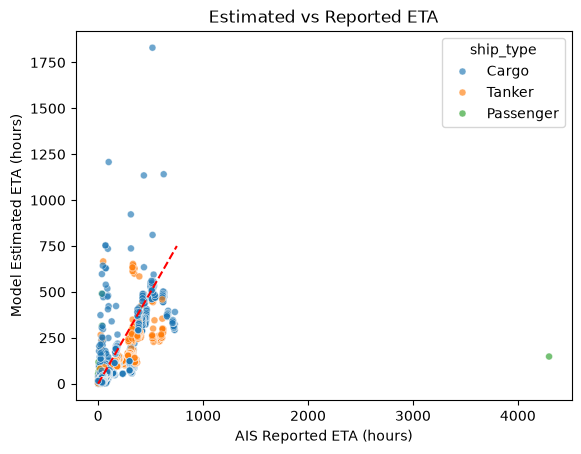

In [12]:
per_vessel = hourly_representative.groupby(['mmsi', 'dest_lat', 'dest_lon'])['eta_discrepancy'].median().reset_index()
final_discrepancy = per_vessel.groupby('mmsi')['eta_discrepancy'].median().reset_index()
vessel_map = hourly_representative.drop_duplicates('mmsi').set_index('mmsi')['ship_type']
final_discrepancy['ship_type'] = final_discrepancy['mmsi'].map(vessel_map)
print(final_discrepancy.describe())
print(final_discrepancy['ship_type'].value_counts())
cargo_discrepancy = final_discrepancy[final_discrepancy['ship_type'] == 'Cargo']
tanker_discrepancy = final_discrepancy[final_discrepancy['ship_type'] == 'Tanker']
passenger_discrepancy = final_discrepancy[final_discrepancy['ship_type'] == 'Passenger']
print(cargo_discrepancy.describe())
print(tanker_discrepancy.describe())
print(passenger_discrepancy.describe())

sns.scatterplot(
    data = hourly_representative,
    x = 'reported_hours',
    y = 'estimated_hours',
    hue = 'ship_type',
    alpha = 0.65,
    s = 25
)

plt.plot([0, 750], [0, 750], color='red', linestyle='--', label='Perfect agreement')

plt.xlabel('AIS Reported ETA (hours)')
plt.ylabel('Model Estimated ETA (hours)')
plt.title('Estimated vs Reported ETA')
plt.savefig('../figures/eta_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

## Final Conclusion
In this analysis we identified differences in ETA discrepancies across three different vessel categories. Tankers displayed the largest negative median discrepancy followed by cargo vessels while passenger vessels seemed to agree more frequently with our model while also having substantially lower variability between discrepancies. These findings suggest that the relationship between AIS-reported ETAs and model-based estimates differs across vessel types. From a logical standpoint passenger vessels tend to operate shorter, more regular routes, while cargo vessels and tankers may experience more variation in speed and voyage conditions. However this analysis does not establish ETA accuracy since we dont have any confirmed arrival times.